# Pipeline illustration figures

Three small figures for the pipeline flowchart, showing what the chain actually produces: **annual
cooling demand for Spain, every model chain, at each warming level.**

They are deliberately not analysis figures. Their job is to show a reader of the flowchart that the
pipeline emits a per-chain time series, and how wide the ensemble spread is on a quantity the paper
leans on — Spanish cooling is the demand term that grows fastest under warming.

**Three separate files**, one per warming level, so each can be placed beside its own box in the
flowchart. Two properties make the set readable as a set:

* **The x axis is the year *within* the twenty-year window, 1 to 20 — not a calendar year.** Each
  chain reaches a given warming level at a different date, so the three windows are different
  calendar periods for every chain. A calendar axis would line chains up at the wrong points of
  their own trajectories.
* **One y limit across all three**, computed before any of them is drawn. The rise in level from
  +1.5 to +3.0 °C is the thing the three figures exist to show together; independent axes would
  hide it completely.

Nine thin lines carry the chains and a bold line the ensemble median, in that level's colour from
the paper's warming-level ramp — so each figure is identifiable at a glance in the flowchart and
the width of the bundle *is* the inter-chain spread.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from cordex2energy_analysis.extremes_analysis import resolve_gwl_period_definitions
from cordex2energy_analysis.plotting_extremes import resolve_model_periods
from cordex2energy_analysis.plotting_publication import FS, MM, WIDTH, fit_width, publication_rc, save

# ── Configuration, copied from the main-figures notebook so the ensemble and the GWL windows are
# the paper's. This notebook needs no event detection and no residual-load run: only the demand
# product and the warming-level windows.
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_DEMAND = PATH_PROCESSED / "energy" / "europe" / "demand"
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_pipeline_publication"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
WARMING_LEVELS = [1.5, 2.0, 3.0]
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]
# The demand product indexes countries by NAME, not ISO2.
COUNTRY = "Spain"
COUNTRY_LABEL = "Spain"
WINDOW_YEARS = 20

# The PAPER's ensemble, discovered the same way the main-figures notebook discovers it: the
# chains that have a residual-load run under the paper's run tag. Globbing the demand directory
# instead would pick up whatever else has been produced, and the figure would then illustrate a
# different ensemble than the one every other figure draws.
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
_tags = {line.split('"')[1]
         for cell in json.load(open("paper_figures_publication.ipynb"))["cells"]
         if cell["cell_type"] == "code"
         for line in cell["source"] if line.startswith("RUN_TAG =")}
assert _tags == {RUN_TAG}, f"run tag drifted from the main figures: {_tags} vs {RUN_TAG}"
models = sorted("_".join(folder.name.split("_")[:-1])
                for folder in PATH_RESIDUAL_LOAD.glob(f"*_{CLIMATE_SCENARIO}")
                if (folder / RUN_TAG).exists())
assert len(models) == 9, f"expected the paper's nine chains, found {len(models)}: {models}"
period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
print(f"{len(models)} chains, levels {period_names}")
print("figures ->", FIGS)


9 chains, levels ['+1.5°C', '+2.0°C', '+3.0°C']
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/paper_pipeline_publication


In [2]:
# ── Annual cooling demand for one country, per chain, per warming level ─────────────────
# The stored product is HOURLY power in GW, so a year's sum is already GW-hours and /1000 gives
# TWh. (An earlier version multiplied by 24 on the assumption of daily means and put Spain at
# 337 TWh/yr of cooling, an order of magnitude above its entire residential electricity demand.)
# A TOTAL rather than a mean is the point: longer, hotter summers add cooling hours as well as
# degrees, and a mean over the year would divide that back out.
started = pd.Timestamp.now()
rows = []
for model in models:
    with xr.open_dataset(PATH_DEMAND / f"{model}_{CLIMATE_SCENARIO}.nc") as dataset:
        series = dataset["cooling_demand"].sel(country=COUNTRY)
        annual = series.resample(time="1YE").sum().load() / 1e3            # GW-hours -> TWh
    windows = resolve_model_periods(period_defs, model)
    for period in period_names:
        window = windows.get(period)
        if window is None:
            continue
        block = annual.sel(time=slice(str(window[0]), str(window[1])))
        for index, value in enumerate(block.values, start=1):
            rows.append(dict(model=model, period=period, year_in_window=index,
                             twh=float(value)))
cooling = pd.DataFrame(rows)
print(f"{len(cooling):,} rows in {(pd.Timestamp.now() - started).seconds}s")

# Nine chains and twenty years in every level, or the three figures are not comparable.
for _period in period_names:
    _block = cooling[cooling.period == _period]
    _counts = _block.groupby("model")["year_in_window"].count()
    assert len(_counts) == len(models), f"{_period}: {len(_counts)} chains, expected {len(models)}"
    assert set(_counts) == {WINDOW_YEARS}, \
        f"{_period}: window lengths {sorted(set(_counts))}, expected {WINDOW_YEARS}"
print(f"every level carries {len(models)} chains x {WINDOW_YEARS} years")

# A sanity bound on the unit arithmetic, not on the physics: Spanish cooling electricity is of
# order 10 TWh/yr today, so anything outside 1-100 means the GW-to-TWh conversion is wrong again.
_span = cooling["twh"]
assert 1.0 < _span.median() < 100.0, \
    f"annual cooling of {_span.median():.1f} TWh/yr is not a plausible unit for {COUNTRY_LABEL}"

print(f"\nAnnual cooling demand, {COUNTRY_LABEL} (TWh/yr), across chains and years:")
for _period in period_names:
    _v = cooling[cooling.period == _period]["twh"]
    print(f"  {_period}  median {_v.median():5.1f}   chain spread of the 20-year mean "
          f"{cooling[cooling.period == _period].groupby('model')['twh'].mean().min():5.1f} - "
          f"{cooling[cooling.period == _period].groupby('model')['twh'].mean().max():5.1f}")


540 rows in 4s
every level carries 9 chains x 20 years

Annual cooling demand, Spain (TWh/yr), across chains and years:
  +1.5°C  median  12.1   chain spread of the 20-year mean  10.5 -  13.9
  +2.0°C  median  13.9   chain spread of the 20-year mean  12.7 -  16.0
  +3.0°C  median  18.9   chain spread of the 20-year mean  17.5 -  23.1


  pipeline_cooling_spain_1p5    57.8 x  41.2 mm   panel 29.6 mm   pdf 33 kB  png 109 kB
  pipeline_cooling_spain_2p0    57.8 x  41.2 mm   panel 29.6 mm   pdf 33 kB  png 105 kB
  pipeline_cooling_spain_3p0    57.8 x  41.2 mm   panel 29.6 mm   pdf 33 kB  png 133 kB
all three share y = (np.float64(7.473258), np.float64(31.636164))
each figure draws 9 chains + median, 20 points each

Ensemble-median annual cooling demand (TWh/yr): +1.5°C 12.0  +2.0°C 13.8  +3.0°C 19.1


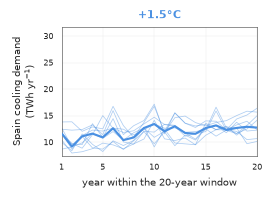

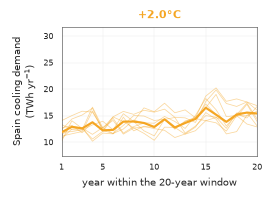

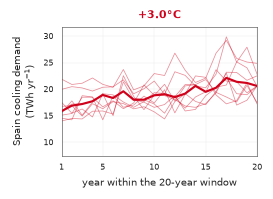

In [3]:
# ── One figure per warming level, sharing a single y limit ──────────────────────────────
# The limit is computed across ALL levels first. Drawn per figure it would autoscale to each
# level's own range, and three panels that each fill their axes would show no warming signal at
# all — which is the one thing the set is for.
Y_TOP = cooling["twh"].max() * 1.06
# NOT anchored at zero. The values run 10-30 TWh/yr, so a zero baseline left the bottom third of
# every panel empty and squeezed the chain bundle — the spread these figures exist to show — into
# what was left. Truncating is safe here in a way it would not be on bars: the three panels share
# this one limit, so the level shift between warming levels is still read off the same ruler.
Y_BOTTOM = cooling["twh"].min() * 0.94
# Derived from the warming levels rather than written out against the period names: those names
# are formatted by resolve_gwl_period_definitions, and a hardcoded key would KeyError silently
# somewhere else in the notebook if that formatting ever changed.
SLUG = {name: f"{level:.1f}".replace(".", "p")
        for name, level in zip(period_names, WARMING_LEVELS)}


def pipeline_panel(period, color):
    """Nine chains thin, the ensemble median bold, in this level's colour."""
    fig, ax = plt.subplots(figsize=(WIDTH * 0.32, 38 * MM))
    block = cooling[cooling.period == period]
    for model, chain in block.groupby("model"):
        chain = chain.sort_values("year_in_window")
        ax.plot(chain["year_in_window"], chain["twh"], lw=0.5, color=color, alpha=0.45, zorder=2)
    median = block.groupby("year_in_window")["twh"].median()
    ax.plot(median.index, median.values, lw=1.4, color=color, zorder=3)

    ax.set_ylim(Y_BOTTOM, Y_TOP)
    ax.set_xlim(1, WINDOW_YEARS)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlabel("year within the 20-year window", fontsize=FS["label"])
    ax.set_ylabel(f"{COUNTRY_LABEL} cooling demand\n(TWh yr$^{{-1}}$)", fontsize=FS["label"])
    ax.set_title(period, fontsize=FS["title"], fontweight="bold", color=color)
    ax.tick_params(labelsize=FS["tick"])
    ax.grid(True, color="0.93", lw=0.3)
    ax.set_axisbelow(True)
    return fig


_limits, _lines = set(), {}
with publication_rc():
    for _period, _color in zip(period_names, GWL_COLORS):
        _fig = pipeline_panel(_period, _color)
        # A third of the page each, so the three sit in a flowchart row without rescaling.
        fit_width(_fig, target_mm=58)
        save(_fig, f"pipeline_cooling_{COUNTRY.lower()}_{SLUG[_period]}", FIGS,
             max_width_mm=60)
        # Measured off the figures that were actually WRITTEN, not off a second set drawn to be
        # measured: those would share a limit by construction and the assertion would prove nothing.
        _limits.add(tuple(round(v, 6) for v in _fig.axes[0].get_ylim()))
        _lines[_period] = [line.get_xydata() for line in _fig.axes[0].lines]
plt.show()

assert len(_limits) == 1, f"the three pipeline figures do not share a y limit: {_limits}"
print(f"all three share y = {sorted(_limits)[0]}")

# Nine chains and a median, each of twenty points, in every figure.
for _period, _drawn in _lines.items():
    assert len(_drawn) == len(models) + 1, \
        f"{_period}: {len(_drawn)} lines drawn, expected {len(models)} chains plus the median"
    _lengths = {len(d) for d in _drawn}
    assert _lengths == {WINDOW_YEARS}, f"{_period}: line lengths {sorted(_lengths)}"
print(f"each figure draws {len(models)} chains + median, {WINDOW_YEARS} points each")

_medians = {p: float(cooling[cooling.period == p].groupby("year_in_window")["twh"].median().mean())
            for p in period_names}
print("\nEnsemble-median annual cooling demand (TWh/yr): "
      + "  ".join(f"{p} {v:.1f}" for p, v in _medians.items()))
assert _medians[period_names[-1]] > _medians[period_names[0]], \
    "cooling demand no longer rises with warming; the three-figure set has nothing to show"
